In [1]:
import json
import subprocess
from datetime import datetime

with open("query_result.json", "r") as f:
    data = json.load(f)


In [2]:
data

{'numberOfRecords': 151,
 'totalNumberOfRecords': 151,
 'records': [{'flare_class': 'M6.6',
   'start_time': '2011-02-13 17:28:00',
   'peak_time': '2011-02-13 17:38:00',
   'end_time': '2011-02-13 17:47:00',
   'active_region_number': 11158,
   'harp_number': 377},
  {'flare_class': 'X2.2',
   'start_time': '2011-02-15 01:44:00',
   'peak_time': '2011-02-15 01:56:00',
   'end_time': '2011-02-15 02:06:00',
   'active_region_number': 11158,
   'harp_number': 377},
  {'flare_class': 'X1.5',
   'start_time': '2011-03-09 23:13:00',
   'peak_time': '2011-03-09 23:23:00',
   'end_time': '2011-03-09 23:29:00',
   'active_region_number': 11166,
   'harp_number': 401},
  {'flare_class': 'M9.3',
   'start_time': '2011-07-30 02:04:00',
   'peak_time': '2011-07-30 02:09:00',
   'end_time': '2011-07-30 02:12:00',
   'active_region_number': 11261,
   'harp_number': 750},
  {'flare_class': 'M6.0',
   'start_time': '2011-08-03 13:17:00',
   'peak_time': '2011-08-03 13:48:00',
   'end_time': '2011-08-0

In [2]:
records = data['records']

m_flares = [
    flare for flare in records if flare["flare_class"].startswith('M')
]

x_flares = [
    flare for flare in records if flare["flare_class"].startswith('X')
]
selected_flares = m_flares[:15] + x_flares[:15]

In [8]:
print(f"M-class available: {len(m_flares)}")
print(f"X-class available: {len(x_flares)}")
print(f"Selected: {len(selected_flares)}")

M-class available: 94
X-class available: 57
Selected: 30


In [3]:
dates = sorted({
    datetime.strptime(
        flare["peak_time"],
        "%Y-%m-%d %H:%M:%S"
    ).strftime("%m/%d/%Y")
    for flare in selected_flares
})

In [10]:
dates

['01/07/2014',
 '01/23/2012',
 '02/13/2011',
 '02/15/2011',
 '03/07/2012',
 '03/09/2011',
 '03/09/2012',
 '03/10/2012',
 '03/29/2014',
 '04/11/2013',
 '04/25/2014',
 '05/10/2012',
 '07/02/2012',
 '07/04/2012',
 '07/05/2012',
 '07/12/2012',
 '07/30/2011',
 '08/03/2011',
 '08/04/2011',
 '09/06/2011',
 '09/07/2011',
 '09/08/2011',
 '09/10/2014',
 '09/25/2011',
 '10/22/2014',
 '10/24/2014',
 '11/08/2013',
 '11/10/2013']

In [15]:
for date in dates:
    cmd = [
        "globalDownload.py",
        "--verbose",
        "--url=https://cedar.openmadrigal.org/",
        "--outputDir=./tec_hdf5",
        '--user_fullname=Amrit+Madabushi',
        "--user_email=am2699@njit.edu",
        '--user_affiliation=NJIT',
        '--format=hdf5',
        f"--startDate={date}",
        f"--endDate={date}",
        "--inst=8000",
        "--kindat=3500"
    ]
    print(f"Downloading TEC for {date}")
    subprocess.run(cmd, check=True)

Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments4/2014/gps/06jan14
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments4/2014/gps/07jan14
2 files being downloaded
Downloaded file ./tec_hdf5/gps140106g.003_0.hdf5
Downloaded file ./tec_hdf5/gps140107g.003_0.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2012/gps/22jan12
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2012/gps/23jan12
2 files being downloaded
Downloaded file ./tec_hdf5/gps120122g.003.hdf5
Downloaded file ./tec_hdf5/gps120123g.003.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/12feb11
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/13feb11
2 files being downloaded
Downloaded file ./tec_hdf5/gps110212g.002.hdf5
Downloaded file ./tec_hdf5/gps110213g.002.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/14feb11
Analyzed exp url https://cedar.openmadrigal.

In [4]:
import h5py
import pandas as pd
import numpy as np
from pathlib import Path

TEC_DIR = Path("tec_hdf5")
CHUNK_SIZE = 250_000

def get_tec_file(flare):
    """Find the daily TEC file corresponding to a flare's peak date."""
    peak = pd.to_datetime(flare["peak_time"])
    date_code = peak.strftime("%y%m%d")

    # print(date_code)
    matches = sorted(TEC_DIR.glob(f"gps{date_code}g.*.hdf5"))

    if not matches:
        raise FileNotFoundError(
            f"No TEC file found for {peak.date()}"
        )
    return matches[0]

def extract_nearest_tec_map(path,target_time):
    """
    Find the TEC snapshot nearest to target_time wtihout loading the entire daily HDF5 into memory.
    """
    target_time = pd.to_datetime(target_time)

    nearest_time = None
    nearest_diff = None

    # PASS 1: find nearest avaliable TEC timestamp
    with h5py.File(path, "r") as f:
        table = f["Data"]["Table Layout"]

        for start in range(0,len(table),CHUNK_SIZE):
            chunk = table[start:start+CHUNK_SIZE]

            times = pd.to_datetime({
                "year": chunk["year"],
                "month": chunk["month"],
                "day": chunk["day"],
                "hour": chunk["hour"],
                "minute": chunk["min"],
                "second": chunk["sec"],
            })

            unique_times = pd.Index(times.unique())

            diffs = abs(unique_times-target_time)
            i = diffs.argmin()

            candidate_time = unique_times[i]
            candidate_diff = diffs[i]

            if nearest_diff is None or candidate_diff < nearest_diff:
                nearest_diff = candidate_diff
                nearest_time = candidate_time
        print(f"Requested: {target_time}")
    print(f"Nearest TEC map: {nearest_time}")
    print(f"Difference: {nearest_diff}")

    # PASS 2: extract only rows belonging to that TEC timestamp
    pieces = []

    with h5py.File(path, "r") as f:
        table = f["Data"]["Table Layout"]

        for start in range(0, len(table), CHUNK_SIZE):
            chunk = table[start:start + CHUNK_SIZE]

            mask = (
                (chunk["year"] == nearest_time.year) &
                (chunk["month"] == nearest_time.month) &
                (chunk["day"] == nearest_time.day) &
                (chunk["hour"] == nearest_time.hour) &
                (chunk["min"] == nearest_time.minute) &
                (chunk["sec"] == nearest_time.second)
            )

            if np.any(mask):
                selected = chunk[mask]

                pieces.append(
                    pd.DataFrame({
                        "gdlat": selected["gdlat"],
                        "glon": selected["glon"],
                        "tec": selected["tec"],
                    })
                )

    if not pieces:
        raise RuntimeError(
            f"No TEC rows found for {nearest_time}"
        )

    tec_map = pd.concat(pieces, ignore_index=True)

    # Madrigal missing-value convention
    tec_map.loc[tec_map["tec"] > 1e20, "tec"] = np.nan

    return nearest_time, tec_map

In [18]:
flare = selected_flares[0]

path = get_tec_file(flare)

print("Flare:", flare["flare_class"], flare["peak_time"])
print("TEC file:", path.name)

tec_time, tec_map = extract_nearest_tec_map(
    path,
    flare["peak_time"]
)

print(tec_map.shape)
print(tec_map.head())

Flare: M6.6 2011-02-13 17:38:00
TEC file: gps110213g.002.hdf5
Requested: 2011-02-13 17:38:00
Nearest TEC map: 2011-02-13 17:37:30
Difference: 0 days 00:00:30
(6687, 3)
   gdlat  glon   tec
0  -90.0 -84.0  66.0
1  -90.0 -82.0  65.9
2  -90.0 -81.0  65.9
3  -90.0 -80.0  65.8
4  -90.0 -79.0  65.7


In [5]:
from pathlib import Path

print("cwd:", Path.cwd())
print("TEC_DIR:", TEC_DIR.resolve())
print("exists:", TEC_DIR.exists())
print("files found:", list(TEC_DIR.glob("gps110213g*.hdf5")))

cwd: /home/amritm/projects/surya-tec-forecasting
TEC_DIR: /home/amritm/projects/surya-tec-forecasting/tec_hdf5
exists: True
files found: [PosixPath('tec_hdf5/gps110213g.002.hdf5')]


# Visualization

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

FIGURE_DIR = Path("figures/tec_maps")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def plot_map(tec_map, timestamp):
    """Plot one global TEC map on the given axes."""
    grid = tec_map.pivot(
        index="gdlat",
        columns="glon",
        values="tec"
    )

    fig,ax = plt.subplots(figsize=(12,5))

    mesh = ax.pcolormesh(
        grid.columns,
        grid.index,
        grid.values,
        shading="auto"
    )

    fig.colorbar(mesh,ax=ax,label="TEC")

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"Global TEC Map —  {timestamp}")

    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

    timestamp = pd.to_datetime(timestamp)
    filename = f"tec_{timestamp.strftime('%Y%m%d_%H%M%S')}.png"
    save_path = FIGURE_DIR / filename

    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"Saved: {save_path}")

    # plt.show()
    plt.close(fig)

    # lats = sorted(map_df["gdlat"].unique())
    # lons = sorted(map_df["glon"].unique())
    # tec_grid = map_df.pivot(index="gdlat", columns="glon", values="tec")

    # # pcolormesh needs cell edges, not centers — shift by 0.5°
    # lat_edges = [l - 0.5 for l in lats] + [lats[-1] + 0.5]
    # lon_edges = [l - 0.5 for l in lons] + [lons[-1] + 0.5]
    # LON, LAT = np.meshgrid(lon_edges, lat_edges)

    # tec_arr = tec_grid.reindex(index=lats, columns=lons).values

    # im = ax.pcolormesh(LON, LAT, tec_arr,
    #                    cmap="viridis", vmin=0, vmax=60,
    #                    shading="flat")
    # ax.set_xlim(-180, 180)
    # ax.set_ylim(-90, 90)
    # ax.set_title(title, fontsize=9, pad=4)
    # ax.set_aspect("equal")
    # ax.tick_params(labelsize=7)
    # # Draw equator and prime meridian for reference
    # ax.axhline(0, color="white", linewidth=0.4, alpha=0.5)
    # ax.axvline(0, color="white", linewidth=0.4, alpha=0.5)
    # return im

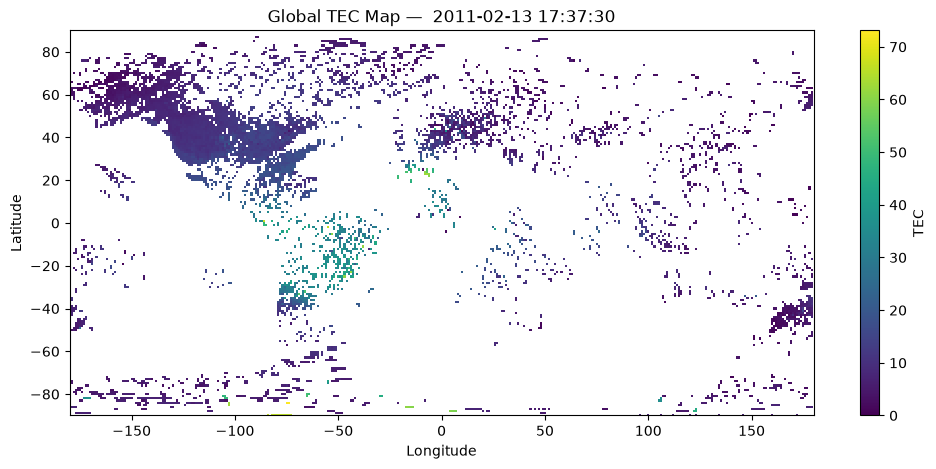

In [ ]:
# plot_map(tec_map,tec_time)

In [7]:
for flare in selected_flares:
    path = get_tec_file(flare)
    peak = pd.to_datetime(flare["peak_time"])

    for offset in [-3,-2, -1, 0, 1, 2, 3]:
        target_time = peak + pd.Timedelta(hours=offset)

        tec_time, tec_map = extract_nearest_tec_map(
            path,
            target_time
        )

        plot_map(tec_map, tec_time)

Requested: 2011-02-13 14:38:00
Nearest TEC map: 2011-02-13 14:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_143730.png
Requested: 2011-02-13 15:38:00
Nearest TEC map: 2011-02-13 15:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_153730.png
Requested: 2011-02-13 16:38:00
Nearest TEC map: 2011-02-13 16:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_163730.png
Requested: 2011-02-13 17:38:00
Nearest TEC map: 2011-02-13 17:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_173730.png
Requested: 2011-02-13 18:38:00
Nearest TEC map: 2011-02-13 18:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_183730.png
Requested: 2011-02-13 19:38:00
Nearest TEC map: 2011-02-13 19:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_193730.png
Requested: 2011-02-13 20:38:00
Nearest TEC map: 2011-02-13 20:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_203